In [1]:
import pandas as pd
import os

In [2]:
FILE = "Employee.csv"
RATE = 1450
BASE_COLS = ["Name", "Age", "Salary", "City"]

In [3]:
def add_derived_columns(data):
    data = data.copy()
    data["Salary_USD"] = (data["Salary"] / RATE).round(2)
    data["Age_Group"] = pd.cut(
        data["Age"],
        bins = [0, 25, 30, float("inf")],
        labels = ["Young", "Mid", "Senior"],
        right=False
)
    data["Salary_Level"] = pd.cut(
    data["Salary"],
    bins = [0, 5000000, 10000000, float("inf")],
    labels = ["Low", "Medium", "High"],
    right=False
)
    return data

In [4]:
if os.path.exists(FILE):
    df = pd.read_csv(FILE)
else:
    df = pd.DataFrame({
        "Name": ['Nickson', 'Cynthia', 'Carmen', 'Afurika', 'Bruce', 'Cedrick', 'Patrick', 'Chance', 'Yvette', 'Norbert'],
        "Age": [25, 23, 20, 24, 26, 27, 22, 29, 37, 30],
        "Salary": [10000000, 5000000, 2000000, 6000000, 7000000, 3000000, 4000000, 9000000, 20000000, 8000000],
        "City": ['Newyork', 'London', 'Paris', 'Dubai', 'Kigali', 'Carfonia', 'Brussels', 'Mumbai', 'Texas', 'Madrid']
    })
    df.to_csv(FILE, index=False)
df = add_derived_columns(df)

In [5]:
while True:
    try:
        print("\n---EMPLOYEE MANAGER---")
        print("1.Show All")
        print("2.Search by City")
        print("3.Sort by Salary")
        print("4.Add Employee")
        print("5.Exit")
        
        choice = input("Choose: ")
        if choice == "1":
            print(df)
        elif choice == "2":
            place = input("Enter the City: ")
            result = df[df['City']==place]
            if result.empty:
                print("No one found")
            else:
                print(result)
        elif choice == "3":
            new = df.sort_values("Salary", ascending=False)
            print(new)
        elif choice == "4":
            name = input("Name: ")
            age = int(input("Age: "))
            salary = int(input("Salary: "))
            city = input("City: ")
            df.loc[len(df)] = [name, age, salary, city]
            df.to_csv(FILE, index=False)
            print("Employee Added Successfully!")
        elif choice == "5":
            print("GOODBYE")
            break
        else:
            print("Invalid Choice")
    except Exception as e:
        print(f"There's an error: {e}")
        


        
        
            


---EMPLOYEE MANAGER---
1.Show All
2.Search by City
3.Sort by Salary
4.Add Employee
5.Exit


Choose:  5


GOODBYE


In [6]:
print(df.dtypes)

Name                 str
Age                int64
Salary             int64
City                 str
Salary_USD       float64
Age_Group       category
Salary_Level    category
dtype: object


In [7]:
df["Age"] = pd.to_numeric(df["Age"])
df["Salary"] = pd.to_numeric(df["Salary"])

In [8]:
print(df.dtypes)

Name                 str
Age                int64
Salary             int64
City                 str
Salary_USD       float64
Age_Group       category
Salary_Level    category
dtype: object


In [9]:
df.loc[0, "Salary"] = 25000000

In [10]:
print(df)

       Name  Age    Salary      City  Salary_USD Age_Group Salary_Level
0   Nickson   25  25000000   Newyork    17241.38       Mid         High
1   Cynthia   23   5250000    London     3620.69     Young       Medium
2    Carmen   20   2100000     Paris     1448.28     Young          Low
3   Afurika   24   6300000     Dubai     4344.83     Young       Medium
4     Bruce   26   7000000    Kigali     4827.59       Mid       Medium
5   Cedrick   27   3150000  Carfonia     2172.41       Mid          Low
6   Patrick   22   4200000  Brussels     2896.55     Young          Low
7    Chance   29   9000000    Mumbai     6206.90       Mid       Medium
8    Yvette   37  20000000     Texas    13793.10    Senior         High
9   Norbert   30   8000000    Madrid     5517.24    Senior       Medium
10    Brain   35  25000000   Arizona    17241.38    Senior         High
11     King   40  20000000    Ottawa    13793.10    Senior         High


In [11]:
df.loc[df["Salary"] < 7000000, "Salary"] = df["Salary"] * 1.05

In [12]:
print(df)

       Name  Age    Salary      City  Salary_USD Age_Group Salary_Level
0   Nickson   25  25000000   Newyork    17241.38       Mid         High
1   Cynthia   23   5512500    London     3620.69     Young       Medium
2    Carmen   20   2205000     Paris     1448.28     Young          Low
3   Afurika   24   6615000     Dubai     4344.83     Young       Medium
4     Bruce   26   7000000    Kigali     4827.59       Mid       Medium
5   Cedrick   27   3307500  Carfonia     2172.41       Mid          Low
6   Patrick   22   4410000  Brussels     2896.55     Young          Low
7    Chance   29   9000000    Mumbai     6206.90       Mid       Medium
8    Yvette   37  20000000     Texas    13793.10    Senior         High
9   Norbert   30   8000000    Madrid     5517.24    Senior       Medium
10    Brain   35  25000000   Arizona    17241.38    Senior         High
11     King   40  20000000    Ottawa    13793.10    Senior         High


In [13]:
df.sort_values("Salary", ascending=False)

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.38,Mid,High
10,Brain,35,25000000,Arizona,17241.38,Senior,High
8,Yvette,37,20000000,Texas,13793.10,Senior,High
11,King,40,20000000,Ottawa,13793.10,Senior,High
7,Chance,29,9000000,Mumbai,6206.90,Mid,Medium
9,Norbert,30,8000000,Madrid,5517.24,Senior,Medium
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium
3,Afurika,24,6615000,Dubai,4344.83,Young,Medium
1,Cynthia,23,5512500,London,3620.69,Young,Medium
6,Patrick,22,4410000,Brussels,2896.55,Young,Low


In [14]:
df

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.38,Mid,High
1,Cynthia,23,5512500,London,3620.69,Young,Medium
2,Carmen,20,2205000,Paris,1448.28,Young,Low
3,Afurika,24,6615000,Dubai,4344.83,Young,Medium
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium
5,Cedrick,27,3307500,Carfonia,2172.41,Mid,Low
6,Patrick,22,4410000,Brussels,2896.55,Young,Low
7,Chance,29,9000000,Mumbai,6206.90,Mid,Medium
8,Yvette,37,20000000,Texas,13793.10,Senior,High
9,Norbert,30,8000000,Madrid,5517.24,Senior,Medium


In [15]:
df.sort_values("Age", ascending=False)

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
11,King,40,20000000,Ottawa,13793.10,Senior,High
8,Yvette,37,20000000,Texas,13793.10,Senior,High
10,Brain,35,25000000,Arizona,17241.38,Senior,High
9,Norbert,30,8000000,Madrid,5517.24,Senior,Medium
7,Chance,29,9000000,Mumbai,6206.90,Mid,Medium
5,Cedrick,27,3307500,Carfonia,2172.41,Mid,Low
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium
0,Nickson,25,25000000,Newyork,17241.38,Mid,High
3,Afurika,24,6615000,Dubai,4344.83,Young,Medium
1,Cynthia,23,5512500,London,3620.69,Young,Medium


In [16]:
df.loc[0:5]

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.38,Mid,High
1,Cynthia,23,5512500,London,3620.69,Young,Medium
2,Carmen,20,2205000,Paris,1448.28,Young,Low
3,Afurika,24,6615000,Dubai,4344.83,Young,Medium
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium
5,Cedrick,27,3307500,Carfonia,2172.41,Mid,Low


In [17]:
df.loc[0:4]

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.38,Mid,High
1,Cynthia,23,5512500,London,3620.69,Young,Medium
2,Carmen,20,2205000,Paris,1448.28,Young,Low
3,Afurika,24,6615000,Dubai,4344.83,Young,Medium
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium


In [18]:
df.loc[0, "Salary"] = 25000000

In [19]:
df.loc[0:4]

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.38,Mid,High
1,Cynthia,23,5512500,London,3620.69,Young,Medium
2,Carmen,20,2205000,Paris,1448.28,Young,Low
3,Afurika,24,6615000,Dubai,4344.83,Young,Medium
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium


In [20]:
df.tail(3)

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
9,Norbert,30,8000000,Madrid,5517.24,Senior,Medium
10,Brain,35,25000000,Arizona,17241.38,Senior,High
11,King,40,20000000,Ottawa,13793.10,Senior,High


In [21]:
df.shape

(12, 7)

In [22]:
df.dtypes

Name                 str
Age                int64
Salary             int64
City                 str
Salary_USD       float64
Age_Group       category
Salary_Level    category
dtype: object

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Name          12 non-null     str     
 1   Age           12 non-null     int64   
 2   Salary        12 non-null     int64   
 3   City          12 non-null     str     
 4   Salary_USD    12 non-null     float64 
 5   Age_Group     12 non-null     category
 6   Salary_Level  12 non-null     category
dtypes: category(2), float64(1), int64(2), str(2)
memory usage: 900.0 bytes


In [24]:
df.describe()

,Age,Salary,Salary_USD
count,12.000000,1.200000e+01,12.000000
mean,28.166667,1.133750e+07,7758.620833
std,6.278873,8.586081e+06,5970.687587
min,20.000000,2.205000e+06,1448.280000
25%,23.750000,5.236875e+06,3439.655000
50%,26.500000,7.500000e+06,5172.415000
75%,31.250000,2.000000e+07,13793.100000
max,40.000000,2.500000e+07,17241.380000


In [25]:
df[["Name", "City"]]

,Name,City
0,Nickson,Newyork
1,Cynthia,London
2,Carmen,Paris
3,Afurika,Dubai
4,Bruce,Kigali
5,Cedrick,Carfonia
6,Patrick,Brussels
7,Chance,Mumbai
8,Yvette,Texas
9,Norbert,Madrid


In [26]:
df.loc[(df["Age"] > 25) & (df["Salary"] > 5000000)]

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium
7,Chance,29,9000000,Mumbai,6206.90,Mid,Medium
8,Yvette,37,20000000,Texas,13793.10,Senior,High
9,Norbert,30,8000000,Madrid,5517.24,Senior,Medium
10,Brain,35,25000000,Arizona,17241.38,Senior,High
11,King,40,20000000,Ottawa,13793.10,Senior,High


In [27]:
df.loc[df["Salary"].idxmax(), "Name"]

'Nickson'

In [28]:
df.loc[df["City"].isin(['London', 'Kigali'])]

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
1,Cynthia,23,5512500,London,3620.69,Young,Medium
4,Bruce,26,7000000,Kigali,4827.59,Mid,Medium


In [29]:
df["Salary_USD"] = df["Salary"] / 1450
df.to_csv(FILE, index=False)

In [30]:
df

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.379310,Mid,High
1,Cynthia,23,5512500,London,3801.724138,Young,Medium
2,Carmen,20,2205000,Paris,1520.689655,Young,Low
3,Afurika,24,6615000,Dubai,4562.068966,Young,Medium
4,Bruce,26,7000000,Kigali,4827.586207,Mid,Medium
5,Cedrick,27,3307500,Carfonia,2281.034483,Mid,Low
6,Patrick,22,4410000,Brussels,3041.379310,Young,Low
7,Chance,29,9000000,Mumbai,6206.896552,Mid,Medium
8,Yvette,37,20000000,Texas,13793.103448,Senior,High
9,Norbert,30,8000000,Madrid,5517.241379,Senior,Medium


In [31]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins = [0, 25, 30, float("inf")],
    labels = ["Young", "Mid", "Senior"],
    right=False
    )
df.to_csv(FILE, index=False)

In [32]:
df

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.379310,Mid,High
1,Cynthia,23,5512500,London,3801.724138,Young,Medium
2,Carmen,20,2205000,Paris,1520.689655,Young,Low
3,Afurika,24,6615000,Dubai,4562.068966,Young,Medium
4,Bruce,26,7000000,Kigali,4827.586207,Mid,Medium
5,Cedrick,27,3307500,Carfonia,2281.034483,Mid,Low
6,Patrick,22,4410000,Brussels,3041.379310,Young,Low
7,Chance,29,9000000,Mumbai,6206.896552,Mid,Medium
8,Yvette,37,20000000,Texas,13793.103448,Senior,High
9,Norbert,30,8000000,Madrid,5517.241379,Senior,Medium


In [33]:
import numpy as np


In [34]:
conditions = [
    df["Salary"] < 5000000,
    (df["Salary"] >= 5000000) & (df["Salary"] < 10000000),
    df["Salary"] >= 10000000
]
choices = ["Low", "Mid", "High"]

df["Salary_Level"] = np.select(conditions, choices, default="unknown")
df.to_csv(FILE, index=False)

# Alternative code :df["Salary_Level"] = pd.cut(
    #df["Salary"],
    #bins = [0, 5000000, 10000000, float("inf")],
    #labels = ["Low", "Medium", "High"],
    #right=False)

In [35]:
df

,Name,Age,Salary,City,Salary_USD,Age_Group,Salary_Level
0,Nickson,25,25000000,Newyork,17241.379310,Mid,High
1,Cynthia,23,5512500,London,3801.724138,Young,Mid
2,Carmen,20,2205000,Paris,1520.689655,Young,Low
3,Afurika,24,6615000,Dubai,4562.068966,Young,Mid
4,Bruce,26,7000000,Kigali,4827.586207,Mid,Mid
5,Cedrick,27,3307500,Carfonia,2281.034483,Mid,Low
6,Patrick,22,4410000,Brussels,3041.379310,Young,Low
7,Chance,29,9000000,Mumbai,6206.896552,Mid,Mid
8,Yvette,37,20000000,Texas,13793.103448,Senior,High
9,Norbert,30,8000000,Madrid,5517.241379,Senior,Mid


In [36]:
df.groupby("Age_Group")["Salary"].mean()

Age_Group
Young      4685625.0
Mid       11076875.0
Senior    18250000.0
Name: Salary, dtype: float64

In [37]:
df.value_counts("Salary_Level")

Salary_Level
Mid     5
High    4
Low     3
Name: count, dtype: int64

In [38]:
city_totals = df.groupby("City")["Salary"].sum().sort_values(ascending=False)
print(city_totals)
print(city_totals.idxmax())

City
Arizona     25000000
Newyork     25000000
Ottawa      20000000
Texas       20000000
Mumbai       9000000
Madrid       8000000
Kigali       7000000
Dubai        6615000
London       5512500
Brussels     4410000
Carfonia     3307500
Paris        2205000
Name: Salary, dtype: int64
Arizona


In [39]:
df["Age"].corr(df["Salary"])

np.float64(0.68614041379901)

In [40]:
# this tells us that we have moderate positive linear relationship. Meaning; as employee ages increases, salary tends to increase. But there's no proof

In [41]:
import matplotlib.pyplot as plt

<Axes: xlabel='Name'>

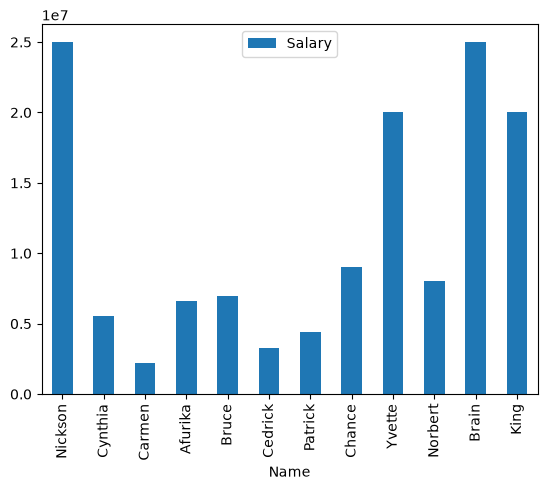

In [42]:
df.plot(kind="bar", x="Name", y="Salary")

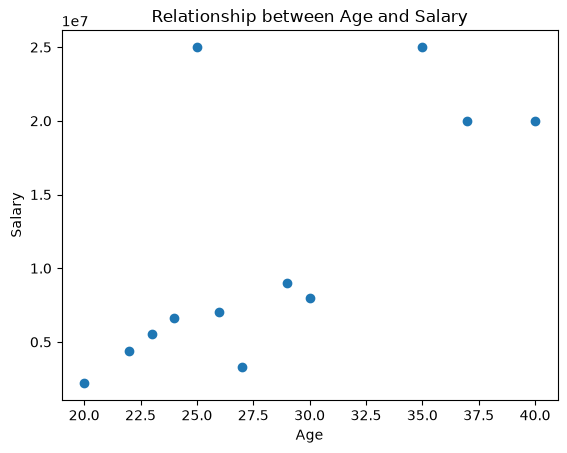

In [43]:
plt.scatter(df["Age"], df["Salary"])

plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Relationship between Age and Salary")
plt.show()

In [ ]:
while True:
    try:
        print("\n---EMPLOYEE MANAGER---")
        print("1.Show All")
        print("2.Search by City")
        print("3.Sort by Salary")
        print("4.Add Employee")
        print("5.Exit")
        
        choice = input("Choose: ")
        if choice == "1":
            print(df)
        elif choice == "2":
            place = input("Enter the City: ")
            result = df[df['City']==place]
            if result.empty:
                print("No one found")
            else:
                print(result)
        elif choice == "3":
            new = df.sort_values("Salary", ascending=False)
            print(new)
        elif choice == "4":
            name = input("Name: ")
            age = int(input("Age: "))
            salary = int(input("Salary: "))
            city = input("City: ")
            df.loc[len(df)] = [name, age, salary, city]
            df.to_csv(FILE, index=False)
            print("Employee Added Successfully!")
        elif choice == "5":
            print("GOODBYE")
            break
        else:
            print("Invalid Choice")
    except Exception as e:
        print(f"There's an error: {e}")


---EMPLOYEE MANAGER---
1.Show All
2.Search by City
3.Sort by Salary
4.Add Employee
5.Exit


In [ ]:
df